# Project Brazilian e-commerce by Olist

## Modeling Schema

<img src=..\docs\assets\data_schema.png width="900">


Source: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

## Data Dictionary

| Features | Description | Tables |
| :--- | :--- | :--- |
| customer_city | customer city name | customers |
| customer_id | key to the orders dataset. Each order has a unique customer_id. | customers, orders |
| customer_state | customer state | customers |
| customer_unique_id | unique identifier of a customer. | customers |
| customer_zip_code_prefix | first five digits of customer zip code | customers |
| freight_value | item freight value item (if an order has more than one item the freight value is splitted between items) | items |
| geolocation_city | city name | geolocation |
| geolocation_lat | latitude | geolocation |
| geolocation_lng | longitude | geolocation |
| geolocation_state | state | geolocation |
| geolocation_zip_code_prefix | first 5 digits of zip code | geolocation |
| order_approved_at | Shows the payment approval timestamp. | orders |
| order_delivered_carrier_date | Shows the order posting timestamp. When it was handled to the logistic partner. | orders |
| order_delivered_customer_date | Shows the actual order delivery date to the customer. | orders |
| order_estimated_delivery_date | Shows the estimated delivery date that was informed to customer at the purchase moment. | orders |
| order_id | order unique identifier | items, payments, reviews, orders |
| order_item_id | sequential number identifying number of items included in the same order | items |
| order_purchase_timestamp | Shows the purchase timestamp. | orders |
| order_status | Reference to the order status (delivered, shipped, etc). | orders |
| payment_installments | number of installments chosen by the customer. | payments |
| payment_sequential | a customer may pay an order with more than one payment method. If he does so, a sequence will be created to | payments |
| payment_type | method of payment chosen by the customer. | payments |
| payment_value | transaction value. | payments |
| price | item price | items |
| product_category_name | root category of product, in Portuguese. | products |
| > product_description_lenght | number of characters extracted from the product description. | products |
| product_height_cm | product height measured in centimeters. | products |
| product_id | product unique identifier | items, products |
| product_length_cm | product length measured in centimeters. | products |
| > product_name_lenght | number of characters extracted from the product name. | products |
| product_photos_qty | number of product published photos. | products |
| product_weight_g | product weight measured in grams. | products |
| product_width_cm | product width measured in centimeters. | products |
| review_answer_timestamp | Shows satisfaction survey answer timestamp. | reviews |
| review_comment_message | Comment message from the review left by the customer, in Portuguese. | reviews |
| review_comment_title | Comment title from the review left by the customer, in Portuguese. | reviews |
| review_creation_date | Shows the date in which the satisfaction survey was sent to the customer. | reviews |
| review_id | unique review identifier | reviews |
| review_score | Note ranging from 1 to 5 given by the customer on a satisfaction survey. | reviews |
| seller_city | seller city name | sellers |
| seller_id | seller unique identifier | items, sellers |
| seller_state | seller state | sellers |
| seller_zip_code_prefix | first 5 digits of seller zip code | sellers |
| shipping_limit_date | Shows the seller shipping limit date for handling the order over to the logistic partner. | items |


In [31]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.eda_utils import dataframe_summary
from src.plots import plot_numeric_distribution, plot_categorical_counts


In [3]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [4]:
pd.reset_option("display.max_rows")

## Reading Data

In [5]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
order_payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
order_reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

In [6]:
dfs = {
    "customers": customers,
    "geolocation": geolocation,
    "items": order_items,
    "payments": order_payments,
    "reviews": order_reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
}

In [7]:
for name, df in dfs.items():
    print(f'{name.upper()} {df.shape}:')
    display(dataframe_summary(df))


CUSTOMERS (99441, 5):


,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
customer_city,str,0,0.0,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,str,0,0.0,99441,06b8999e2fba1a1fbc88172c00ba8bc7,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,str,0,0.0,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,str,0,0.0,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,int64,0,0.0,14994,22790,142,35137.474583,29797.938996,11347.0,24416.0,58900.0,1003.0,99990.0,0.779025,-0.788204


GEOLOCATION (1000163, 5):


,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
geolocation_city,str,0,0.0,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_lat,float64,0,0.0,717360,-27.102099,314,-21.176153,5.715866,-23.603546,-22.919377,-19.979620,-36.605374,45.065933,1.565147,2.850097
geolocation_lng,float64,0,0.0,717613,-48.629613,314,-46.390541,4.269748,-48.573172,-46.637879,-43.767709,-101.466766,121.105394,-0.102417,4.727051
geolocation_state,str,0,0.0,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_zip_code_prefix,int64,0,0.0,19015,24220,1146,36574.166466,30549.335710,11075.000000,26530.000000,63504.000000,1001.000000,99990.000000,0.694494,-0.941226


ITEMS (112650, 7):


...

,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
customer_id,str,0,0.00000,99441,9ef432eb6251297304e76186b10a928d,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_approved_at,str,160,0.16090,90733,2018-02-27 04:31:10,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_delivered_carrier_date,str,1783,1.79302,81018,2018-05-09 15:48:00,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_delivered_customer_date,str,2965,2.98167,95664,2018-05-14 20:02:44,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_estimated_delivery_date,str,0,0.00000,459,2017-12-20 00:00:00,522,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,str,0,0.00000,99441,e481f51cbdc54678b7cc49136f2d6af7,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_purchase_timestamp,str,0,0.00000,98875,2018-03-31 15:08:21,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,str,0,0.00000,8,delivered,96478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


PRODUCTS (32951, 9):


,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
product_category_name,str,610,1.85123,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_description_lenght,float64,610,1.85123,2960,404.0,94,771.495285,635.115225,339.0,595.0,972.0,4.0,3992.0,1.962093,4.828923
product_height_cm,float64,2,0.00607,102,10.0,2548,16.937661,13.637554,8.0,13.0,21.0,2.0,105.0,2.140061,6.678619
product_id,str,0,0.00000,32951,1e9e8ef04dbcff4541ed26657ea517e5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_length_cm,float64,2,0.00607,99,16.0,5520,30.815078,16.914458,18.0,25.0,38.0,7.0,105.0,1.750460,3.513618
product_name_lenght,float64,610,1.85123,66,60.0,2182,48.476949,10.245741,42.0,51.0,57.0,5.0,76.0,-0.903222,0.192563
product_photos_qty,float64,610,1.85123,19,1.0,16489,2.188986,1.736766,1.0,1.0,3.0,1.0,20.0,2.193409,7.263534
product_weight_g,float64,2,0.00607,2204,200.0,2084,2276.472488,4282.038731,300.0,700.0,1900.0,0.0,40425.0,3.604860,15.133565
product_width_cm,float64,2,0.00607,95,11.0,3718,23.196728,12.079047,15.0,20.0,30.0,6.0,118.0,1.670971,4.073126


SELLERS (3095, 4):


,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
seller_city,str,0,0.0,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,str,0,0.0,3095,3442f8959a84dea7ee197c632cb2df15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,str,0,0.0,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,int64,0,0.0,2246,14940,49,32291.059451,32713.45383,7093.5,14940.0,64552.5,1001.0,99730.0,0.916092,-0.858264


Para facilitar a analise decidi juntar todas as tabelas exceto geolocation (por enquanto), com isso surgem algumas perguntas que devem ser respondidas a primeira delas é "O que representa uma linha no meu dataset unificado?", após breve analise cheguei a conclusão que o nivel mais granular que ainda faz sentido é o de item do pedido (order_items), pois produto, vendedor, frete e preço variam por item e não por um pedido inteiro. Dito isto, a segunda pergunta a ser repondida é "Como as demais tabelas se relacionam com o item do pedido?" o que pode ser respondido pela relação de cardinalidade:

| Tabela | Relação com "item do pedido" |
|---|---|
| `orders` | 1 pedido → N itens (então 1:m em relação ao grão) |
| `order_items` | **é o próprio grão** |
| `products` | N itens podem repetir o mesmo produto (m:1) |
| `sellers` | N itens podem repetir o mesmo vendedor (m:1) |
| `customers` | 1 pedido = 1 cliente, mas N itens do mesmo pedido repetem o cliente (m:1 em relação ao grão) |
| `payments` | 1 pedido pode ter N pagamentos — **não bate direto com o grão "item"** |
| `reviews` | 1 pedido normalmente tem 1 review, raramente mais — **também não bate diretamente** |

payments e reviews são relações "por pedido", não "por item". Se eu simplesmente desse merge direto delas contra o dataset já expandido por item, qualquer pedido com 2 itens e 2 pagamentos viraria 4 linhas (2×2) — um produto cartesiano que não representa nada real, só um artefato do merge

Ordem de merge utilizada:

```
orders → customers → order_items → products → sellers → payments (agregado) → reviews (dedup)
```

- **`orders + customers` primeiro**: relação 1:1 real (cada pedido tem exatamente um cliente), então é seguro e não altera a contagem de linhas. Fiz isso cedo porque é "barato" e não introduz risco.
- **`+ order_items`**: aqui, e só aqui, o dataset "explode" de fato — de propósito, porque é essa a granularidade que eu quero.
- **`+ products` e `+ sellers`**: ambos são m:1 em relação ao grão atual (vários itens podem apontar pro mesmo produto/vendedor), então o merge não altera a contagem de linhas — só adiciona colunas.
- **`+ payments`**: como *não* é m:1 em relação ao grão, eu não faço merge direto. Primeiro **agrego** (`groupby('order_id')`) para colapsar a granularidade de payments para "por pedido", e só depois faço o merge — agora sim é m:1 seguro.
- **`+ reviews`**: mesmo raciocínio — dedupliquei por `order_id` antes, transformando numa relação segura.



In [8]:
%run ../src/data_processing.py

2026-08-27 21:00:41,988 [INFO] Carregando customers de ..\data\raw\olist_customers_dataset.csv
2026-08-27 21:00:42,198 [INFO] Carregando orders de ..\data\raw\olist_orders_dataset.csv
2026-08-27 21:00:42,666 [INFO] Carregando order_items de ..\data\raw\olist_order_items_dataset.csv
2026-08-27 21:00:43,043 [INFO] Carregando payments de ..\data\raw\olist_order_payments_dataset.csv
2026-08-27 21:00:43,190 [INFO] Carregando reviews de ..\data\raw\olist_order_reviews_dataset.csv
2026-08-27 21:00:43,682 [INFO] Carregando products de ..\data\raw\olist_products_dataset.csv
2026-08-27 21:00:43,759 [INFO] Carregando sellers de ..\data\raw\olist_sellers_dataset.csv
2026-08-27 21:00:43,772 [INFO] Carregando geolocation de ..\data\raw\olist_geolocation_dataset.csv
2026-08-27 21:00:44,800 [INFO] Carregando category_translation de ..\data\raw\product_category_name_translation.csv
2026-08-27 21:00:45,201 [INFO] orders + customers -> (99441, 12)
2026-08-27 21:00:45,474 [INFO] + order_items -> (112650, 

In [9]:
df_merged = pd.read_parquet("../data/interim/olist_merged.parquet")
df_merged.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value_total,payment_installments_max,payment_types,n_payment_methods,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,38.71,1.0,credit_card | voucher,2.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio correto e em boas condições. Apenas a caixa que veio bem amassada e danificada, o que ficará chato, pois se trata de um presente.",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,141.46,1.0,boleto,1.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,179.12,3.0,credit_card,1.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58


In [10]:
dataframe_summary(df_merged)

,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
customer_city,str,0,0.00000,4110,sao paulo,17808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,str,0,0.00000,98666,fc3d1daec319d62d49bfb5e1f83123e9,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,str,0,0.00000,27,SP,47449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,str,0,0.00000,95420,c8460e4251689ba205045f3ea17884a1,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,int64,0,0.00000,14976,22790,154,35119.309090,29866.120801,11310.00,24340.00,59028.75,1003.00,99990.00,0.780165,-0.792801
freight_value,float64,0,0.00000,6999,15.1,3707,19.990320,15.806405,13.08,16.26,21.15,0.00,409.68,5.639870,59.788253
n_payment_methods,float64,3,0.00266,2,1.0,110159,1.022087,0.146966,1.00,1.00,1.00,1.00,2.00,6.503833,40.300553
order_approved_at,str,15,0.01332,90174,2018-02-24 03:20:27,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_delivered_carrier_date,str,1194,1.05992,81017,2018-05-09 15:48:00,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df_processed = pd.read_parquet("../data/processed/olist_processed.parquet")
df_processed.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value_total,payment_installments_max,payment_types,n_payment_methods,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,38.71,1.0,credit_card | voucher,2.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio correto e em boas condições. Apenas a caixa que veio bem amassada e danificada, o que ficará chato, pois se trata de um presente.",2017-10-11,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,141.46,1.0,boleto,1.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,179.12,3.0,credit_card,1.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18,2018-08-22 19:07:58


In [12]:
dataframe_summary(df_processed)

,dtype,total_null,percent_null,unique,top,freq,mean,std,25%,50%,75%,min,max,skew,kurtosis
feature,,,,,,,,,,,,,,,
customer_city,str,0,0.00000,4110,sao paulo,17808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,str,0,0.00000,98666,fc3d1daec319d62d49bfb5e1f83123e9,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,str,0,0.00000,27,SP,47449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,str,0,0.00000,95420,c8460e4251689ba205045f3ea17884a1,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,int64,0,0.00000,14976,22790,154,35119.309090,29866.120801,11310.00,24340.00,59028.75,1003,99990,0.780165,-0.792801
freight_value,float64,0,0.00000,6999,15.1,3707,19.990320,15.806405,13.08,16.26,21.15,0.0,409.68,5.639870,59.788253
n_payment_methods,float64,3,0.00266,2,1.0,110159,1.022087,0.146966,1.00,1.00,1.00,1.0,2.0,6.503833,40.300553
order_approved_at,datetime64[us],15,0.01332,90174,2018-02-24 03:20:27,23,NaN,NaN,NaN,NaN,NaN,2016-09-15 12:16:38,2018-09-03 17:40:06,NaN,NaN
order_delivered_carrier_date,datetime64[us],1194,1.05992,81017,2018-05-09 15:48:00,48,NaN,NaN,NaN,NaN,NaN,2016-10-08 10:34:01,2018-09-11 19:48:28,NaN,NaN


In [14]:
(df_processed.groupby(['order_id'])['order_item_id'].value_counts() > 1).sum()

np.int64(0)

Isso significa que não há items duplicados

In [15]:
df_processed[df_processed['payment_installments_max'].isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value_total,payment_installments_max,payment_types,n_payment_methods,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
34802,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,beleza_saude,34.0,1036.0,1.0,1000.0,16.0,16.0,16.0,health_beauty,81810,curitiba,PR,NaN,NaN,NaN,NaN,6916ca4502d6d3bfd39818759d55d536,1.0,NaN,nao recebi o produto e nem resposta da empresa,2016-10-06,2016-10-07 18:32:28
34803,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,beleza_saude,34.0,1036.0,1.0,1000.0,16.0,16.0,16.0,health_beauty,81810,curitiba,PR,NaN,NaN,NaN,NaN,6916ca4502d6d3bfd39818759d55d536,1.0,NaN,nao recebi o produto e nem resposta da empresa,2016-10-06,2016-10-07 18:32:28
34804,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,beleza_saude,34.0,1036.0,1.0,1000.0,16.0,16.0,16.0,health_beauty,81810,curitiba,PR,NaN,NaN,NaN,NaN,6916ca4502d6d3bfd39818759d55d536,1.0,NaN,nao recebi o produto e nem resposta da empresa,2016-10-06,2016-10-07 18:32:28


In [16]:
df_processed[df_processed['payment_installments_max'].isna()]['order_id'].value_counts()

order_id
bfbd0f9bdef84302105ad712db648a6c    3
Name: count, dtype: int64

Há apenas um cliente sem informações de pagamento registradas, provavelmente durante o merge com a tabela payments não foi encontrado o order_id

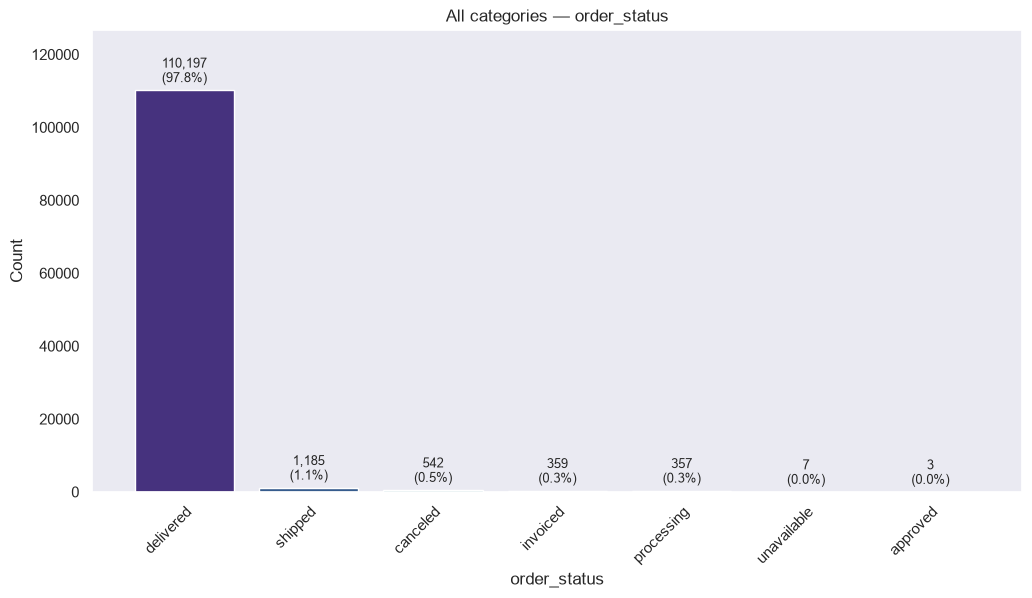

In [37]:
plot_categorical_counts(df_processed, "order_status", multicolor=True);